# Laboratório 10 — Miniprojeto Integrador

## Pipeline de Processamento de Imagens

### Objetivo
Desenvolver um pipeline que reúna os conhecimentos
adquiridos nos laboratórios anteriores.

### Etapas planejadas
1. Carregar uma fotografia.
2. Analisar suas dimensões e canais.
3. Converter para escala de cinza.
4. Redimensionar preservando a proporção.
5. Aplicar filtros de imagem.
6. Preparar uma versão para inteligência artificial.
7. Visualizar e salvar os resultados.


Dimensões (largura, altura): (1021, 1600)
Formato da matriz: (1600, 1021, 3)
Tipo dos dados: uint8


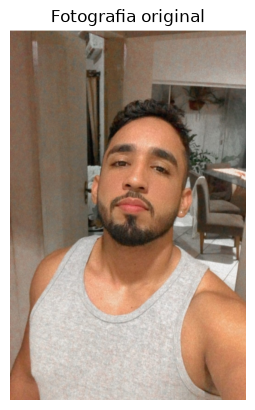

In [1]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Carregar a fotografia
foto = Image.open("../imagens/PAULO.jpeg").convert("RGB")

# Converter para matriz NumPy
matriz = np.array(foto)

# Informações da imagem
print("Dimensões (largura, altura):", foto.size)
print("Formato da matriz:", matriz.shape)
print("Tipo dos dados:", matriz.dtype)

# Visualizar a fotografia
plt.imshow(foto)
plt.axis("off")
plt.title("Fotografia original")
plt.show()


Modo original: RGB
Modo cinza: L
Formato RGB: (1600, 1021, 3)
Formato cinza: (1600, 1021)


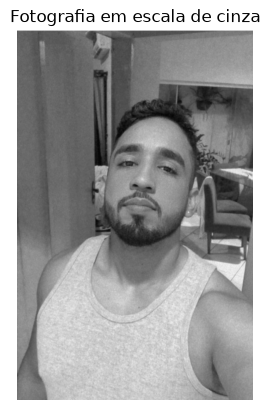

In [2]:

# Converter a fotografia para escala de cinza
foto_cinza = foto.convert("L")

# Transformar em matriz NumPy
matriz_cinza = np.array(foto_cinza)

# Verificar os resultados
print("Modo original:", foto.mode)
print("Modo cinza:", foto_cinza.mode)
print("Formato RGB:", matriz.shape)
print("Formato cinza:", matriz_cinza.shape)

# Exibir a fotografia em escala de cinza
plt.imshow(foto_cinza, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.title("Fotografia em escala de cinza")
plt.show()


Dimensões originais: (1021, 1600)
Dimensões redimensionadas: (255, 400)


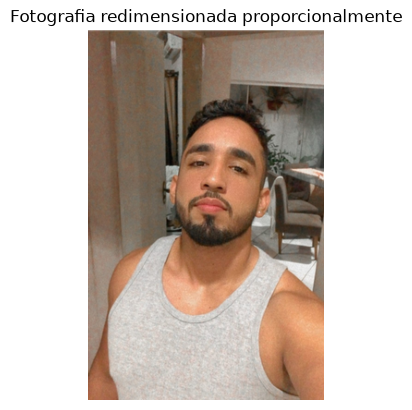

In [3]:

# Criar uma cópia da fotografia
foto_redimensionada = foto.copy()

# Redimensionar mantendo a proporção
foto_redimensionada.thumbnail(
    (400, 400),
    resample=Image.Resampling.LANCZOS
)

# Comparar as dimensões
print("Dimensões originais:", foto.size)
print("Dimensões redimensionadas:", foto_redimensionada.size)

# Exibir o resultado
plt.imshow(foto_redimensionada)
plt.axis("off")
plt.title("Fotografia redimensionada proporcionalmente")
plt.show()


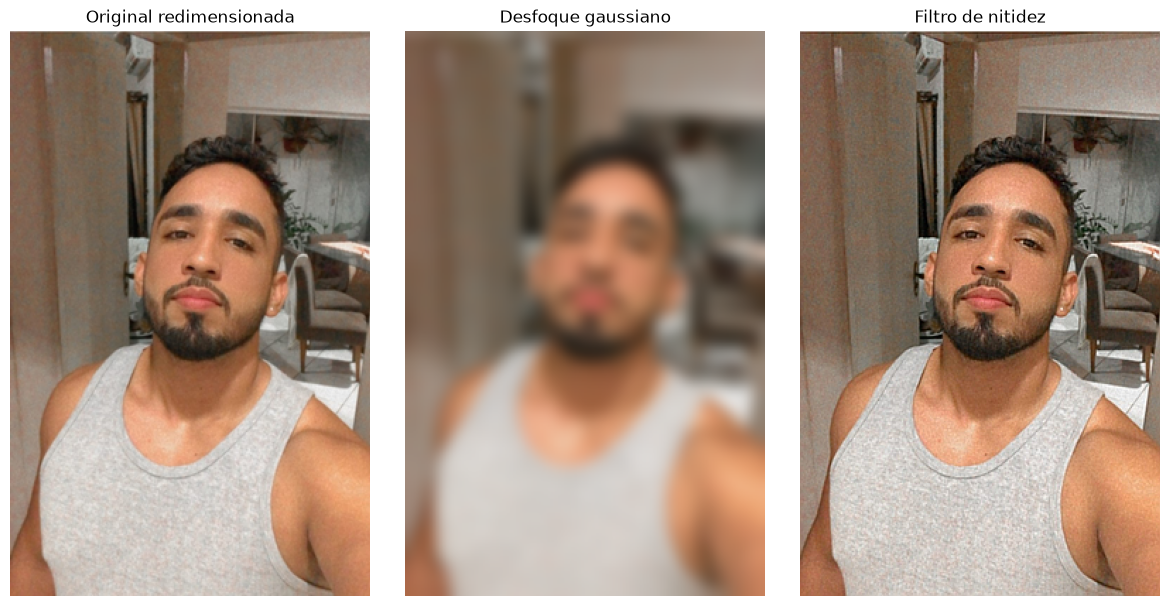

In [4]:

from PIL import ImageFilter

# Aplicar filtros à imagem redimensionada
foto_desfocada = foto_redimensionada.filter(
    ImageFilter.GaussianBlur(radius=5)
)

foto_nitida = foto_redimensionada.filter(
    ImageFilter.SHARPEN
)

# Comparar as três versões
fig, eixos = plt.subplots(1, 3, figsize=(12, 6))

eixos[0].imshow(foto_redimensionada)
eixos[0].set_title("Original redimensionada")

eixos[1].imshow(foto_desfocada)
eixos[1].set_title("Desfoque gaussiano")

eixos[2].imshow(foto_nitida)
eixos[2].set_title("Filtro de nitidez")

for eixo in eixos:
    eixo.axis("off")

plt.tight_layout()
plt.show()


In [5]:

# 1. Padronizar as dimensões para 224 × 224
foto_ia = foto.resize(
    (224, 224),
    resample=Image.Resampling.LANCZOS
)

# 2. Converter para matriz NumPy
matriz_ia = np.array(foto_ia)

# 3. Normalizar os pixels para a escala de 0 a 1
matriz_normalizada = matriz_ia.astype("float32") / 255.0

# 4. Adicionar a dimensão de batch
lote_ia = np.expand_dims(matriz_normalizada, axis=0)

# 5. Verificar os resultados
print("Dimensões:", foto_ia.size)
print("Formato RGB:", matriz_ia.shape)
print("Tipo normalizado:", matriz_normalizada.dtype)
print("Formato do batch:", lote_ia.shape)
print("Menor valor:", matriz_normalizada.min())
print("Maior valor:", matriz_normalizada.max())


Dimensões: (224, 224)
Formato RGB: (224, 224, 3)
Tipo normalizado: float32
Formato do batch: (1, 224, 224, 3)
Menor valor: 0.0
Maior valor: 0.9843137


In [6]:

from pathlib import Path

# Criar pasta para os resultados
pasta_resultados = Path("../imagens/resultados_lab10")
pasta_resultados.mkdir(parents=True, exist_ok=True)

# Salvar as imagens processadas
foto_cinza.save(pasta_resultados / "PAULO_cinza.png")
foto_redimensionada.save(pasta_resultados / "PAULO_redimensionada.png")
foto_desfocada.save(pasta_resultados / "PAULO_desfocada.png")
foto_nitida.save(pasta_resultados / "PAULO_nitida.png")
foto_ia.save(pasta_resultados / "PAULO_preparada_ia.png")

# Conferir os arquivos
for arquivo in sorted(pasta_resultados.glob("*.png")):
    print(arquivo.name)


PAULO_cinza.png
PAULO_desfocada.png
PAULO_nitida.png
PAULO_preparada_ia.png
PAULO_redimensionada.png


In [7]:

# Criar duas versões da fotografia
foto_resize = foto.resize((300, 300))

foto_thumbnail = foto.copy()
foto_thumbnail.thumbnail((300, 300))

# Comparar os resultados
print("Original:", foto.size)
print("Resize:", foto_resize.size)
print("Thumbnail:", foto_thumbnail.size)


Original: (1021, 1600)
Resize: (300, 300)
Thumbnail: (191, 300)
